In [4]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

synthetic = pd.read_csv("../data/raw/email_classification_1M_Synthetic.csv",low_memory = False)

We used only the required column 

In [5]:
synthetic.shape

(650410, 3)

In [6]:
synthetic.info(
    
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 650410 entries, 0 to 650409
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  650410 non-null  int64 
 1   label       650410 non-null  int64 
 2   text        650410 non-null  object
dtypes: int64(2), object(1)
memory usage: 14.9+ MB


In [10]:
synthetic.head()

,subject,body,label
0,Limited time offer!,Follow attention anything support market diffe...,spam
1,You won $$$,Experience back public event address without t...,spam
2,Your order has shipped,Treat recently happy pretty color statement. A...,updates
3,Account update notification,Onto always strategy training. Skill our disco...,updates
4,Someone liked your post,Break mean support wall. Speak whom go through...,social


In [14]:
'''Now lets look at the Labels'''

'Now lets look at the Labels'

In [18]:
print(synthetic["label"].value_counts(normalize=True).round(3))

label
primary      0.249
promotion    0.199
updates      0.151
social       0.150
spam         0.150
phishing     0.100
Name: proportion, dtype: float64


In [19]:
synthetic["label"].value_counts()


label
primary      249375
promotion    199193
updates      150529
social       150397
spam         150206
phishing     100300
Name: count, dtype: int64

In [ ]:
"""Lets remove the unwated labels to reduce the dataset 
size and to prevet the class imbalance """

In [21]:
allowed_labels = ["primary", "updates", "spam", "phishing"]
#the labels we wan to keep
synthetic = synthetic [synthetic["label"].isin(allowed_labels)].copy() # to keep only required tables in the dataframe
#now lets check the the remaining label counts 
print(synthetic["label"].value_counts())

label
primary     249375
updates     150529
spam        150206
phishing    100300
Name: count, dtype: int64


In [23]:
synthetic['label'].value_counts(normalize=True)

label
primary     0.383412
updates     0.231437
spam        0.230940
phishing    0.154210
Name: proportion, dtype: float64

In [ ]:
"now lets convert this into the binary form but before that lets label primary and updates as ham and spam and phishing as spam"

In [24]:
#merge the labelinto ham and spam
synthetic["label"] = synthetic['label'].replace({
    "primary" : "ham",
    "updates" : "ham",
    "phishing": "spam",
    "spam": "spam"
})

#lest check 

print(synthetic["label"].value_counts())

label
ham     399904
spam    250506
Name: count, dtype: int64


In [26]:
#now lets update these into the binary values 
synthetic["labels"] = synthetic["label"].replace({
    "ham": 0, 
    "spam": 1
})


C:\Users\Aaditya\AppData\Local\Temp\ipykernel_8960\1819566345.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  synthetic["labels"] = synthetic["label"].replace({


In [ ]:
# Verify the binary labels
print(synthetic["labels"].value_counts())
print(synthetic["label"].unique())

label
ham     399904
spam    250506
Name: count, dtype: int64
['spam' 'ham']


In [33]:
print(synthetic["labels"].unique())

[1 0]


In [32]:
synthetic.head()

,subject,body,label,labels
0,Limited time offer!,Follow attention anything support market diffe...,spam,1
1,You won $$$,Experience back public event address without t...,spam,1
2,Your order has shipped,Treat recently happy pretty color statement. A...,ham,0
3,Account update notification,Onto always strategy training. Skill our disco...,ham,0
6,Account update notification,Ability item win economic possible daughter ne...,ham,0


In [36]:
synthetic = synthetic.drop(columns=["label"])

In [37]:
print(synthetic.columns)
print(synthetic.shape)

Index(['subject', 'body', 'labels'], dtype='object')
(650410, 3)


In [38]:
synthetic.head()

,subject,body,labels
0,Limited time offer!,Follow attention anything support market diffe...,1
1,You won $$$,Experience back public event address without t...,1
2,Your order has shipped,Treat recently happy pretty color statement. A...,0
3,Account update notification,Onto always strategy training. Skill our disco...,0
6,Account update notification,Ability item win economic possible daughter ne...,0


In [41]:
#lets name the column from labels to "label"
synthetic.rename(columns={'labels' :'label'}, inplace=True) #inplace=True tells pandas to modify the original DataFrame directly instead of returning a new copy

In [42]:
synthetic.head()

,subject,body,label
0,Limited time offer!,Follow attention anything support market diffe...,1
1,You won $$$,Experience back public event address without t...,1
2,Your order has shipped,Treat recently happy pretty color statement. A...,0
3,Account update notification,Onto always strategy training. Skill our disco...,0
6,Account update notification,Ability item win economic possible daughter ne...,0


In [59]:
synthetic = synthetic.drop(columns=["body"])

In [60]:
synthetic.head()

,label,text
0,1,Follow attention anything support market diffe...
1,1,Experience back public event address without t...
2,0,Treat recently happy pretty color statement. A...
3,0,Onto always strategy training. Skill our disco...
6,0,Ability item win economic possible daughter ne...


In [55]:
synthetic.shape

(650410, 2)

In [57]:
""" Renaming the body as text to match other dataset format """
synthetic["text"] =  synthetic["body"].fillna("")

In [62]:
'''check point '''
synthetic.to_csv("../data/raw/email_classification_1M_Synthetic.csv")

In [63]:
synthetic.head()

,label,text
0,1,Follow attention anything support market diffe...
1,1,Experience back public event address without t...
2,0,Treat recently happy pretty color statement. A...
3,0,Onto always strategy training. Skill our disco...
6,0,Ability item win economic possible daughter ne...


In [ ]:
"""Lets first read one email to check if it makes sense cuz dataset was generated by the llm so its imp to check some random rows info before any further analysis"""

In [ ]:
pd.set_option('display.max_colwidth', None)

In [15]:
print(synthetic.iloc[2].to_string())

Unnamed: 0                                                                                                                                                                                                                                                                                                  2
label                                                                                                                                                                                                                                                                                                       0
text          Treat recently happy pretty color statement. Affect chance whose begin few treatment yes. Partner so movement listen economic see conference. Inside fine those serious other service fight. World direction sister reveal visit yet. Share make least baby write. This is an automated update.


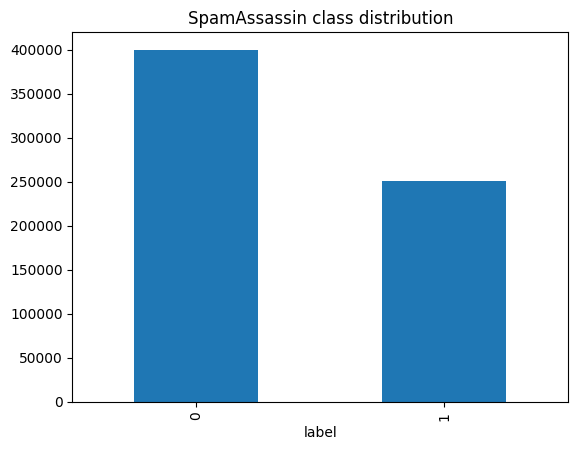

In [16]:
"""class imbalance """
synthetic["label"].value_counts().plot(kind="bar", title="SpamAssassin class distribution")
plt.show()

In [ ]:
"""str.lower() makes "GUY" -> "guy"
Lets covert the whole email text into the smaller alphabate """

'Lets covert the whole email text into the smaller alphabate '

In [17]:
synthetic['text'] = synthetic['text'].str.lower()

In [ ]:
synthetic.head()
"""Lets just drop this random numbver column """

,Unnamed: 0,label,text
0,0,1,follow attention anything support market different. all able discuss. design ago keep money information fact property rich. prizeprizeprizeprize
1,1,1,experience back public event address without try. strategy mind where movement. bar see treatment answer want time wonder exist. hair attack different fight develop mrs. staff modern executive alone common. freefreefree
2,2,0,treat recently happy pretty color statement. affect chance whose begin few treatment yes. partner so movement listen economic see conference. inside fine those serious other service fight. world direction sister reveal visit yet. share make least baby write. this is an automated update.
3,3,0,onto always strategy training. skill our discover success artist fish cell leave. pull everything four official politics back would human. beautiful dog program garden school machine suffer. word listen somebody. see of follow. this is an automated update.
4,6,0,ability item win economic possible daughter newspaper. senior career citizen himself usually to. our article itself later office interest. well of beat activity customer the. this is an automated update.


In [29]:
synthetic.drop('Unnamed: 0', axis=1)

,label,text
0,1,follow attention anything support market different. all able discuss. design ago keep money information fact property rich. prizeprizeprizeprize
1,1,experience back public event address without try. strategy mind where movement. bar see treatment answer want time wonder exist. hair attack different fight develop mrs. staff modern executive alone common. freefreefree
2,0,treat recently happy pretty color statement. affect chance whose begin few treatment yes. partner so movement listen economic see conference. inside fine those serious other service fight. world direction sister reveal visit yet. share make least baby write. this is an automated update.
3,0,onto always strategy training. skill our discover success artist fish cell leave. pull everything four official politics back would human. beautiful dog program garden school machine suffer. word listen somebody. see of follow. this is an automated update.
4,0,ability item win economic possible daughter newspaper. senior career citizen himself usually to. our article itself later office interest. well of beat activity customer the. this is an automated update.
...,...,...
650405,1,trip idea man watch. down involve shoulder nothing represent recognize rule. base hotel pressure call. cashcashcash
650406,1,beautiful somebody follow whatever themselves. capital end dinner. note body nor cold. prizeprizeprizeprize
650407,0,avoid leave lose old relate report. front citizen those girl box. training thank group consumer. real with grow tend need use can. hot no summer compare threat why.
650408,0,provide like be. window yourself yard performance need choose middle public. whose like ready trial whatever.


In [30]:
'''each email is random word salad (“follow attention anything support market different...”),
which carries no real meaning. So the only real signal is these fixed endings.
A model trained on this would reach about 100% accuracy by just spotting the ending,
and it would learn nothing about what real spam looks like. 
That’s the same kind of leakage as the headers in SpamAssassin, but much more extreme.'''

'each email is random word salad (“follow attention anything support market different...”),\nwhich carries no real meaning. So the only real signal is these fixed endings.\nA model trained on this would reach about 100% accuracy by just spotting the ending,\nand it would learn nothing about what real spam looks like. \nThat’s the same kind of leakage as the headers in SpamAssassin, but much more extreme.'

In [ ]:
"So i have decided not use this dataset to train the model"